Using backend: tensorflow

2022-11-09 16:19:25.034198: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcudart.so.11.0
2022-11-09 16:19:26.251178: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcuda.so.1
2022-11-09 16:19:26.326622: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1733] Found device 0 with properties: 
pciBusID: 0000:81:00.0 name: Quadro RTX 8000 computeCapability: 7.5
coreClock: 1.77GHz coreCount: 72 deviceMemorySize: 47.46GiB deviceMemoryBandwidth: 625.94GiB/s
2022-11-09 16:19:26.326648: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcudart.so.11.0
2022-11-09 16:19:26.329317: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublas.so.11
2022-11-09 16:19:26.329353: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dyn

Enable just-in-time compilation with XLA.

Disable just-in-time compilation with XLA.

[1, 1000]
no uniform points
Compiling model...
'compile' took 0.000549 s



2022-11-09 16:19:27.357403: I tensorflow/core/platform/cpu_feature_guard.cc:142] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2022-11-09 16:19:27.365384: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1733] Found device 0 with properties: 
pciBusID: 0000:81:00.0 name: Quadro RTX 8000 computeCapability: 7.5
coreClock: 1.77GHz coreCount: 72 deviceMemorySize: 47.46GiB deviceMemoryBandwidth: 625.94GiB/s
2022-11-09 16:19:27.372987: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1871] Adding visible gpu devices: 0
2022-11-09 16:19:27.373260: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcudart.so.11.0
2022-11-09 16:19:28.330557: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1258] Device interconnect StreamExecu

Training model...



2022-11-09 16:19:30.998402: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:176] None of the MLIR Optimization Passes are enabled (registered 2)
2022-11-09 16:19:31.026237: I tensorflow/core/platform/profile_utils/cpu_utils.cc:114] CPU Frequency: 3000030000 Hz
2022-11-09 16:19:31.272163: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublas.so.11
2022-11-09 16:19:32.180441: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublasLt.so.11


Step      Train loss              Test loss               Test metric
0         [2.29e+05, 2.59e+01]    [2.34e+05, 2.55e+01]    []  
1000      [8.54e+03, 8.12e+03]    [8.82e+03, 8.95e+03]    []  
2000      [2.96e+03, 5.44e+03]    [3.13e+03, 6.25e+03]    []  
3000      [1.83e+03, 3.92e+03]    [1.93e+03, 4.62e+03]    []  
4000      [1.47e+03, 3.15e+03]    [1.57e+03, 3.77e+03]    []  
5000      [9.47e+02, 2.71e+03]    [1.02e+03, 3.19e+03]    []  
6000      [9.20e+02, 1.96e+03]    [9.83e+02, 2.38e+03]    []  
7000      [7.91e+02, 2.14e+03]    [8.59e+02, 2.51e+03]    []  
8000      [8.65e+02, 2.26e+03]    [9.29e+02, 2.62e+03]    []  
9000      [5.51e+02, 2.74e+03]    [5.99e+02, 3.08e+03]    []  
10000     [7.75e+02, 1.65e+03]    [8.14e+02, 1.91e+03]    []  
11000     [5.37e+02, 1.39e+03]    [5.93e+02, 1.64e+03]    []  
12000     [5.00e+02, 1.20e+03]    [5.54e+02, 1.43e+03]    []  
13000     [3.93e+02, 1.30e+03]    [4.31e+02, 1.53e+03]    []  
14000     [3.20e+02, 9.96e+02]    [3.76e+02, 1.2

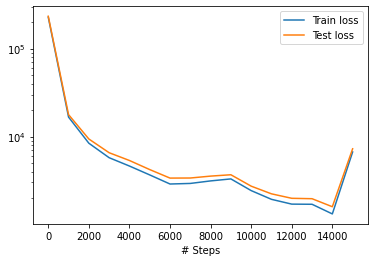

In [1]:
import os
os.environ['DDEBACKEND'] = 'tensorflow'
os.environ['CUDA_VISIBLE_DEVICES'] = '4'

import deepxde as dde 
dde.config.disable_xla_jit()

#class TensorGeometryXTime:
import numpy as np

class GeometryXGeometry:
    def __init__(self, geometry, k):
        self.geometry = geometry
        self.dim = geometry.dim ** k
        self.k = k
    
    def random_points(self, n, random="pseudo"):
        xx = []
        for i in range(self.k):
            xx.append(self.geometry.random_points(n, random=random))
        return np.hstack(xx)
    
    def uniform_points(self, n, boundary=False):
        print('no uniform points')
        return self.random_points(n)
    

"""Backend supported: tensorflow.compat.v1, tensorflow, pytorch"""
import deepxde as dde
import numpy as np

# General parameters
n = 1
k = 2

N_f = 5000
N_f_test = 5000

seed = 1234
dde.config.set_random_seed(seed)
weights = [1000 for i in range(k)]
weights[0] = 1
print(weights)

epochs = 15000
parameters = [1e-2, 2, 350, "sin"] 

# Define sine function
if dde.backend.backend_name == "pytorch":
    sin = dde.backend.pytorch.sin
else:
    from deepxde.backend import tf
    sin = tf.sin

learning_rate, num_dense_layers, num_dense_nodes, activation = parameters


def pde(x, y):
    V0, V1 = y[:, 0:1], y[:, 1:2]
    
    dV0_xx = dde.grad.hessian(y, x, component=0, i=0, j=0)
    dV0_yy = dde.grad.hessian(y, x, component=0, i=1, j=1)
    
    dV1_xx = dde.grad.hessian(y, x, component=1, i=2, j=2)
    dV1_yy = dde.grad.hessian(y, x, component=1, i=3, j=3)
    
    #F = k0 ** 4 * sin(k0 * x[:, 0:1]) * sin(k0 * x[:, 1:2]) * sin(k0 * x[:, 2:3]) * sin(k0 * x[:, 3:4])
    
    dist = tf.abs(x[:, 0:1] - x[:, 2:3]) 
    F =  k0 ** 4 * tf.exp(- dist * 10)
    L1 = - dV0_xx - dV0_yy - k0 ** 2 * V0 - F
    L2 = - dV1_xx - dV1_yy - k0 ** 2 * V1 - V0
    return [L1, L2]


def func(x):
    f1 = np.sin(k0 * x[:, 0:1]) * np.sin(k0 * x[:, 1:2])
    f2 = np.sin(k0 * x[:, 2:3]) * np.sin(k0 * x[:, 3:4])

    res_list = k * [None]
    
    for i in range(k-1):
        res_list[i] = 0 * f1
    res_list[-1] = f1 * f2
    return np.hstack(res_list)


def transform(x, y):
    res1 = x[:, 0:1] * (1 - x[:, 0:1]) * x[:, 1:2] * (1 - x[:, 1:2])
    res2 = x[:, 2:3] * (1 - x[:, 2:3]) * x[:, 3:4] * (1 - x[:, 3:4])

    y_list = [y[:, i:i+1] for i in range(k)]
    
    ys_list = k * [None]
    for i in range(k-1):
        ys_list[i] = y_list[i]
    ys_list[-1] = res1 * res2 * y_list[-1]
    ys = tf.concat(ys_list, axis=1)
    return ys


geom = dde.geometry.Rectangle([0, 0], [1, 1])
Geom = GeometryXGeometry(geom,2)    

k0 = 2 * np.pi * n
wave_len = 1 / n

data = dde.data.PDE(
    Geom,
    pde,
    train_distribution = 'pseudo',
    num_domain=N_f,
    bcs = [],
    num_test=N_f_test,
)

net = dde.nn.FNN(
    [2 * k] + [num_dense_nodes] * num_dense_layers + [k], activation, "Glorot uniform"
)

net.apply_output_transform(transform)

model = dde.Model(data, net)

model.compile("adam", lr=learning_rate, loss_weights=weights)
#model.compile("adam", lr=learning_rate, metrics=[l2_error], loss_weights=weights, decay = ("inverse time", 10000, 0.5))

losshistory, train_state = model.train(epochs=epochs)
dde.saveplot(losshistory, train_state, issave=True, isplot=True)
    

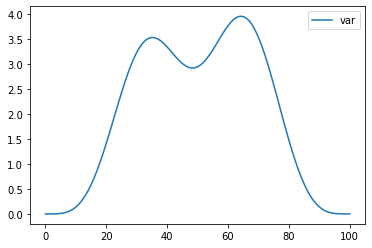

In [2]:
from matplotlib import pyplot as plt
x = np.array([np.arange(101)/100]).T
x_list = [x.T for i in range(2 * k)]
xx = np.concatenate(x_list).T
sol = func(xx)[:, k-1:k]
pred = model.predict(xx)[:, k-1:k]

plt.plot(pred.ravel(), label=r'var')
plt.legend()

In [5]:
u_sca.min(), u_sca.max()
# (0.0, 5.545436)

(0.0, 5.545436)

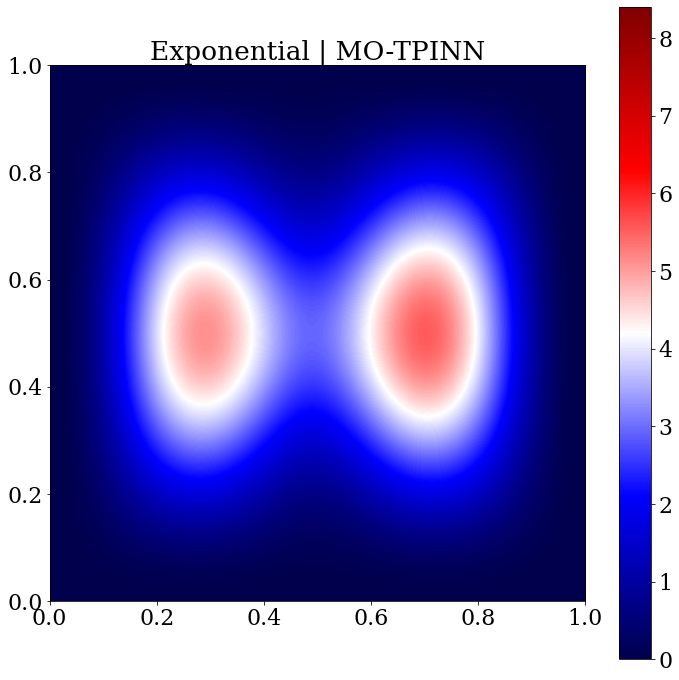

In [7]:
from matplotlib import pyplot as plt
'''            Evaluate field over a specified grid of points              '''
# Square grid with 10 points per wavelength in each direction
Nx = 100
Ny = Nx

vmin = 0
vmax = 8.4

# Grid points
xmin, xmax, ymin, ymax = [0,1,0,1]
plot_grid = np.mgrid[xmin:xmax:Nx * 1j, ymin:ymax:Ny * 1j]
points = np.vstack((plot_grid[0].ravel(),
                    plot_grid[1].ravel(),
                    np.zeros(plot_grid[0].size)))

points_2d = points[:2, :]
points_4d = np.hstack([points_2d.T, points_2d.T])

u_sca = model.predict(points_4d)[:, k-1:k]
u_sca = u_sca.reshape((Nx, Ny))

'''                  Compare against analytical solution                    '''
# Uncomment to perform comparison, takes a few seconds to run


'''                     Plot field and save figure                          '''
plt.rc('font', family='serif', size=22)



fig, (ax1) = plt.subplots(1, 1, sharey=True, figsize = (12,12))

pcm = ax1.imshow(np.fliplr(u_sca).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label='MO-TPINNs', vmin=vmin, vmax=vmax)

#ax1.axis('off')
fig.colorbar(pcm, ax = ax1)
ax1.set_title('Exponential | MO-TPINN')
plt.savefig('Exponential-MO.pdf')

In [4]:
u_sca.max()

5.545436